# Studying with and without AI

In [1]:
import sqlite3

connection = sqlite3.connect(":memory:")
connection.executescript("""
PRAGMA foreign_keys=ON;
BEGIN;
CREATE TABLE study (
 study_id TEXT PRIMARY KEY, citation TEXT NOT NULL,
 publication_year INTEGER NOT NULL CHECK(publication_year>=1900),
 level TEXT NOT NULL CHECK(level IN ('high school','university')),
 subject TEXT NOT NULL, setting TEXT NOT NULL, design TEXT NOT NULL,
 source_url TEXT NOT NULL UNIQUE
) STRICT;
CREATE TABLE study_condition (
 study_id TEXT NOT NULL REFERENCES study(study_id), condition_code TEXT NOT NULL,
 label TEXT NOT NULL, ai_mode TEXT NOT NULL CHECK(ai_mode IN ('none','general chat','structured tutor')),
 description TEXT NOT NULL,
 PRIMARY KEY(study_id,condition_code), UNIQUE(study_id,label)
) STRICT;
CREATE TABLE outcome (
 study_id TEXT NOT NULL REFERENCES study(study_id), outcome_code TEXT NOT NULL,
 label TEXT NOT NULL, dimension TEXT NOT NULL CHECK(dimension IN ('speed','quality')),
 phase TEXT NOT NULL CHECK(phase IN ('lesson','practice','post-test')),
 unit TEXT NOT NULL CHECK(unit IN ('minutes','points','normalized score','percent')),
 PRIMARY KEY(study_id,outcome_code)
) STRICT;
CREATE TABLE result (
 result_id INTEGER PRIMARY KEY,
 study_id TEXT NOT NULL, condition_code TEXT NOT NULL, outcome_code TEXT NOT NULL,
 statistic TEXT NOT NULL CHECK(statistic IN ('mean','median','scheduled','share','adjusted difference')),
 value REAL NOT NULL, comparator_code TEXT,
 standard_error REAL CHECK(standard_error>0), sample_n INTEGER CHECK(sample_n>0),
 source_locator TEXT NOT NULL CHECK(length(trim(source_locator))>0), note TEXT NOT NULL,
 FOREIGN KEY(study_id,condition_code) REFERENCES study_condition(study_id,condition_code),
 FOREIGN KEY(study_id,comparator_code) REFERENCES study_condition(study_id,condition_code),
 FOREIGN KEY(study_id,outcome_code) REFERENCES outcome(study_id,outcome_code),
 CHECK((statistic='adjusted difference' AND comparator_code IS NOT NULL
        AND comparator_code<>condition_code AND standard_error IS NOT NULL)
       OR (statistic<>'adjusted difference' AND comparator_code IS NULL
           AND standard_error IS NULL AND value>=0)),
 CHECK(statistic<>'share' OR value BETWEEN 0 AND 100)
) STRICT;
CREATE UNIQUE INDEX unique_summary ON result(study_id,condition_code,outcome_code,statistic)
 WHERE comparator_code IS NULL;
CREATE UNIQUE INDEX unique_contrast ON result(study_id,condition_code,outcome_code,statistic,comparator_code)
 WHERE comparator_code IS NOT NULL;
COMMIT;
""")
print("SQLite", sqlite3.sqlite_version)

SQLite 3.53.1


### Seed data

In [2]:
connection.executescript("""
PRAGMA foreign_keys=ON;
BEGIN;
INSERT INTO study VALUES
('BASTANI25','Bastani et al. (2025), PNAS',2025,'high school','Mathematics','Grades 9–11 at one school in Türkiye, nearly 1,000 students','Classroom-randomized field experiment','https://doi.org/10.1073/pnas.2422633122'),
('KESTIN25','Kestin et al. (2025), Scientific Reports',2025,'university','Introductory physics','Harvard University, 194 eligible undergraduates','Randomized crossover over two lessons','https://doi.org/10.1038/s41598-025-97652-6');

INSERT INTO study_condition VALUES
('BASTANI25','control','Textbook and notes','none','Standard resources during practice'),
('BASTANI25','base','GPT Base','general chat','Standard GPT-4 chat during practice'),
('BASTANI25','tutor','GPT Tutor','structured tutor','GPT-4 with teacher-provided hints during practice'),
('KESTIN25','class','Active learning class','none','Instructor-led classroom lesson'),
('KESTIN25','tutor','AI tutor','structured tutor','Self-paced lesson at home using a structured AI tutor');

INSERT INTO outcome VALUES
('BASTANI25','practice','Practice score','quality','practice','normalized score'),
('BASTANI25','exam','Unaided exam score','quality','post-test','normalized score'),
('KESTIN25','quiz','Immediate post-test score','quality','post-test','points'),
('KESTIN25','duration','Lesson time on task','speed','lesson','minutes'),
('KESTIN25','under60','AI lesson times under 60 minutes','speed','lesson','percent');

INSERT INTO result VALUES
(1,'BASTANI25','control','practice','mean',0.284,NULL,NULL,NULL,'Table 1, column 1','Control-arm mean on a 0–1 scale'),
(2,'BASTANI25','control','exam','mean',0.321,NULL,NULL,NULL,'Table 1, column 2','Control-arm mean on a 0–1 scale'),
(3,'BASTANI25','base','practice','adjusted difference',0.137,'control',0.031,2848,'Table 1, column 1','Intention-to-treat estimate, p < 0.01. N counts model observations.'),
(4,'BASTANI25','tutor','practice','adjusted difference',0.361,'control',0.032,2848,'Table 1, column 1','Intention-to-treat estimate, p < 0.01. N counts model observations.'),
(5,'BASTANI25','base','exam','adjusted difference',-0.054,'control',0.022,2848,'Table 1, column 2','Intention-to-treat estimate, p < 0.05. N counts model observations.'),
(6,'BASTANI25','tutor','exam','adjusted difference',-0.004,'control',0.013,2848,'Table 1, column 2','Estimate statistically indistinguishable from zero. N counts model observations.'),
(7,'KESTIN25','class','quiz','median',3.5,NULL,NULL,174,'Results, Learning gains: post-test scores','Pooled across two lessons. N counts post-test observations.'),
(8,'KESTIN25','tutor','quiz','median',4.5,NULL,NULL,142,'Results, Learning gains: post-test scores','Pooled across two lessons. N counts post-test observations.'),
(9,'KESTIN25','class','duration','scheduled',60,NULL,NULL,NULL,'Results, Time on task and Fig. 2','Class benchmark calculated as 75 scheduled minutes minus 15 minutes for tests.'),
(10,'KESTIN25','tutor','duration','median',49,NULL,NULL,NULL,'Results, Time on task and Fig. 2','Platform-tracked time on task.'),
(11,'KESTIN25','tutor','under60','share',70,NULL,NULL,NULL,'Results, Time on task and Fig. 2','Reported percentage below the classroom benchmark.');
COMMIT;
""")
for table in ("study", "study_condition", "outcome", "result"):
    count = connection.execute(f"SELECT COUNT(*) FROM {table}").fetchone()[0]
    print(f"{table}: {count} rows")

study: 2 rows
study_condition: 5 rows
outcome: 5 rows
result: 11 rows


### Entity relationship diagram

```mermaid
erDiagram
    direction LR
    STUDY ||--o{ STUDY_CONDITION : defines
    STUDY ||--o{ OUTCOME : measures
    STUDY_CONDITION ||--o{ RESULT : "primary condition"
    STUDY_CONDITION |o--o{ RESULT : "comparator condition"
    OUTCOME ||--o{ RESULT : describes
    STUDY {
        text study_id PK
        text citation
        int publication_year
        text level
        text subject
        text setting
        text design
        text source_url UK
    }
    STUDY_CONDITION {
        text study_id PK,FK
        text condition_code PK
        text label
        text ai_mode
        text description
    }
    OUTCOME {
        text study_id PK,FK
        text outcome_code PK
        text label
        text dimension
        text phase
        text unit
    }
    RESULT {
        int result_id PK
        text study_id FK
        text condition_code FK
        text outcome_code FK
        text comparator_code FK "optional"
        text statistic
        real value
        real standard_error
        int sample_n
        text source_locator
        text note
    }
```


### Queries

In [3]:
def run_query(sql):
    cursor = connection.execute(sql)
    rows = cursor.fetchall()
    headings = [column[0] for column in cursor.description]
    display_rows = [headings, *[[str(value) for value in row] for row in rows]]
    widths = [max(len(value) for value in column) for column in zip(*display_rows)]
    for row in display_rows:
        print(" | ".join(value.ljust(width) for value, width in zip(row, widths)).rstrip())
    return rows

#### Q1 Negative adjusted estimates

Two exam coefficients are negative. The paper reports statistical significance for the GPT Base estimate.

In [4]:
q1 = run_query("""
-- Q1. Filter the reported estimates for negative effects.
SELECT study_id, condition_code, outcome_code, value, standard_error, note
FROM result
WHERE statistic='adjusted difference' AND value<0
ORDER BY value
""")

study_id  | condition_code | outcome_code | value  | standard_error | note
BASTANI25 | base           | exam         | -0.054 | 0.022          | Intention-to-treat estimate, p < 0.05. N counts model observations.
BASTANI25 | tutor          | exam         | -0.004 | 0.013          | Estimate statistically indistinguishable from zero. N counts model observations.


#### Q2 Speed evidence and sources

The joined rows retain the 49-minute logged median, 60-minute schedule-derived benchmark and 70% share below the benchmark.

In [5]:
q2 = run_query("""
-- Q2. Join speed records to their methods, units and source.
SELECT s.citation, c.label AS study_method, o.label AS outcome, r.statistic,
       r.value, o.unit, r.source_locator
FROM result AS r
JOIN study AS s USING(study_id)
JOIN study_condition AS c USING(study_id,condition_code)
JOIN outcome AS o USING(study_id,outcome_code)
WHERE o.dimension='speed'
ORDER BY r.result_id
""")

citation                                 | study_method          | outcome                          | statistic | value | unit    | source_locator
Kestin et al. (2025), Scientific Reports | Active learning class | Lesson time on task              | scheduled | 60.0  | minutes | Results, Time on task and Fig. 2
Kestin et al. (2025), Scientific Reports | AI tutor              | Lesson time on task              | median    | 49.0  | minutes | Results, Time on task and Fig. 2
Kestin et al. (2025), Scientific Reports | AI tutor              | AI lesson times under 60 minutes | share     | 70.0  | percent | Results, Time on task and Fig. 2


#### Q3 Evidence inventory

Eight quality records come from two studies. Three speed records come from the university study.

In [6]:
q3 = run_query("""
-- Q3. Count evidence rows and source studies by dimension.
SELECT o.dimension, COUNT(*) AS result_rows, COUNT(DISTINCT r.study_id) AS studies
FROM result AS r JOIN outcome AS o USING(study_id,outcome_code)
GROUP BY o.dimension ORDER BY o.dimension
""")

dimension | result_rows | studies
quality   | 8           | 2
speed     | 3           | 1


#### Q4 Methods with both dimensions

The class and AI tutor conditions in the university trial both have speed and quality records.

In [7]:
q4 = run_query("""
-- Q4. Find methods that have both speed and quality evidence.
SELECT s.level, c.label AS study_method, COUNT(DISTINCT o.dimension) AS dimensions,
       COUNT(*) AS result_rows
FROM result AS r
JOIN study AS s USING(study_id)
JOIN study_condition AS c USING(study_id,condition_code)
JOIN outcome AS o USING(study_id,outcome_code)
GROUP BY s.study_id,c.condition_code
HAVING COUNT(DISTINCT o.dimension)=2
ORDER BY c.label
""")

level      | study_method          | dimensions | result_rows
university | AI tutor              | 2          | 3
university | Active learning class | 2          | 2


#### Q5 School practice and exam effects

The GPT Base coefficient changes from +13.7 percentage points during practice to −5.4 on the unaided exam. The GPT Tutor exam estimate is −0.4 and statistically indistinguishable from zero.

In [8]:
q5 = run_query("""
-- Q5. Pivot school effects and convert the 0–1 scale to percentage points.
SELECT c.label AS study_method,
       ROUND(100*MAX(CASE WHEN r.outcome_code='practice' THEN r.value END),1) AS practice_pp,
       ROUND(100*MAX(CASE WHEN r.outcome_code='exam' THEN r.value END),1) AS exam_pp
FROM result AS r JOIN study_condition AS c USING(study_id,condition_code)
WHERE r.study_id='BASTANI25' AND r.statistic='adjusted difference'
  AND r.comparator_code='control'
GROUP BY c.condition_code
HAVING COUNT(DISTINCT r.outcome_code)=2
ORDER BY c.label
""")

study_method | practice_pp | exam_pp
GPT Base     | 13.7        | -5.4
GPT Tutor    | 36.1        | -0.4


#### Q6 University lesson time and post-test scores

The AI tutor median time is 11 minutes below the class benchmark. The immediate post-test median is 1 point higher.

In [9]:
q6 = run_query("""
-- Q6. Compare class and tutor on the same university outcomes.
-- The time difference is descriptive because the class value is scheduled.
SELECT o.outcome_code, o.label AS outcome, o.unit,
       class.statistic AS class_statistic, class.value AS class_value,
       tutor.statistic AS ai_statistic, tutor.value AS ai_value,
       ROUND(tutor.value-class.value,1) AS ai_minus_class
FROM result AS class
JOIN result AS tutor
  ON tutor.study_id=class.study_id AND tutor.outcome_code=class.outcome_code
JOIN outcome AS o ON o.study_id=class.study_id AND o.outcome_code=class.outcome_code
WHERE class.study_id='KESTIN25'
  AND class.condition_code='class' AND tutor.condition_code='tutor'
  AND ((o.outcome_code='duration' AND class.statistic='scheduled' AND tutor.statistic='median')
    OR (o.outcome_code='quiz' AND class.statistic='median' AND tutor.statistic='median'))
ORDER BY o.outcome_code
""")

outcome_code | outcome                   | unit    | class_statistic | class_value | ai_statistic | ai_value | ai_minus_class
duration     | Lesson time on task       | minutes | scheduled       | 60.0        | median       | 49.0     | -11.0
quiz         | Immediate post-test score | points  | median          | 3.5         | median       | 4.5      | 1.0


### Matplotlib visualizations

School effects use the textbook-and-notes comparator. University lesson time compares a platform-logged median with a schedule-derived benchmark.

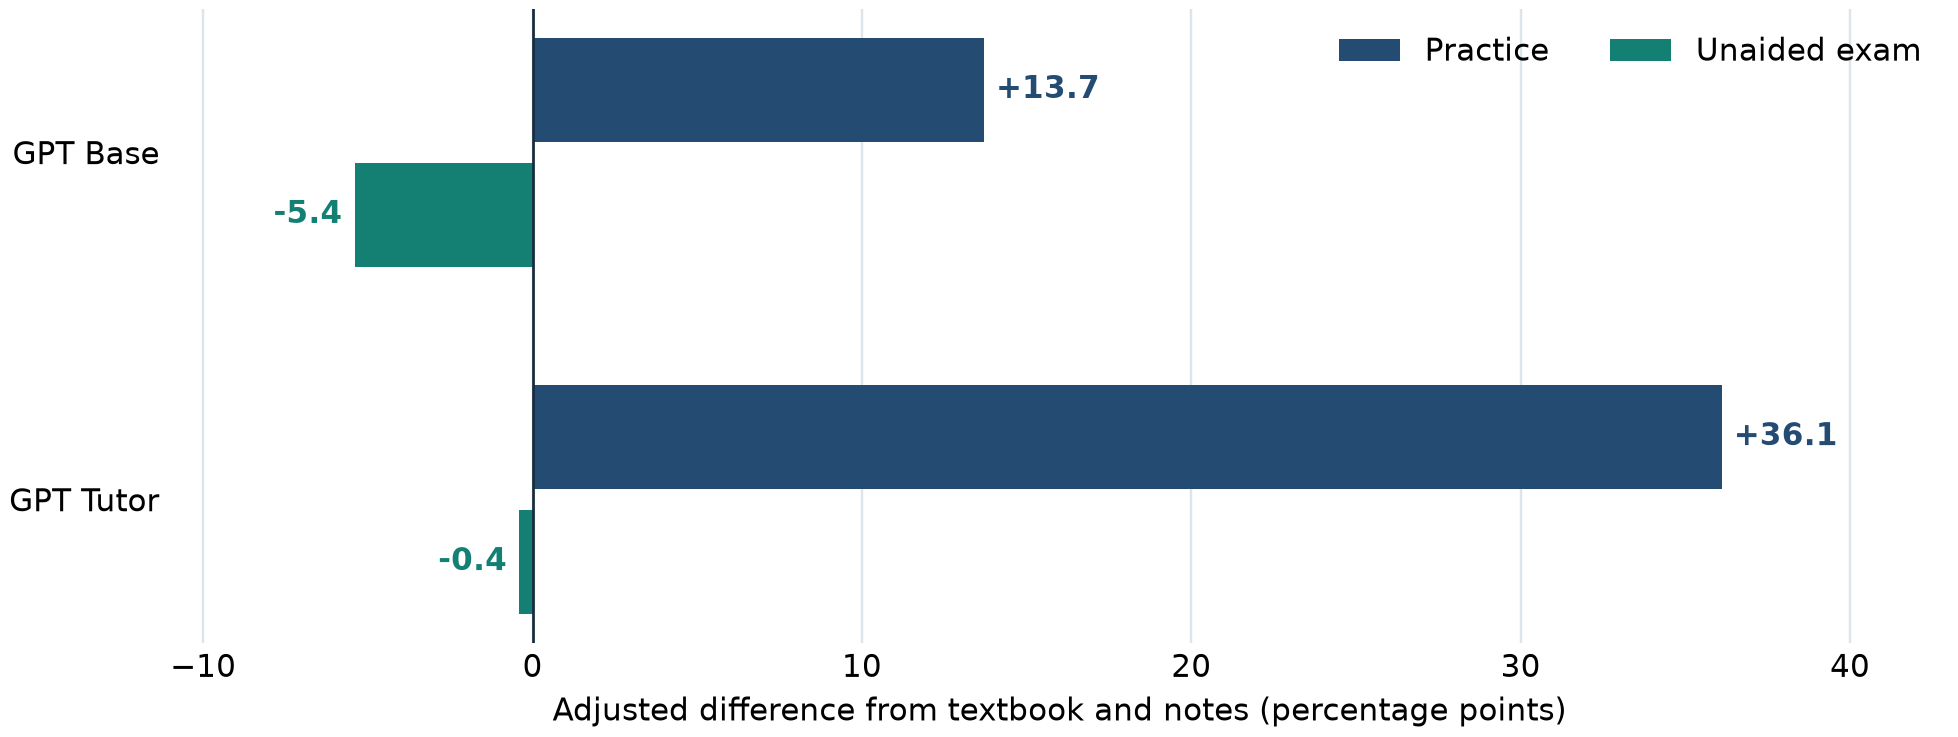

In [10]:
import matplotlib.pyplot as plt

blue, teal, ink = "#244c72", "#148074", "#172c40"
methods, practice, exam = zip(*q5)
positions = list(range(len(methods)))

fig, ax = plt.subplots(figsize=(8.9, 3.35), layout="constrained")
for label, values, offset, color in [
    ("Practice", practice, -0.18, blue),
    ("Unaided exam", exam, 0.18, teal),
]:
    bars = ax.barh([y + offset for y in positions], values, height=0.30, color=color, label=label)
    ax.bar_label(bars, fmt="%+.1f", padding=4, color=color, fontweight="bold")
ax.set_yticks(positions, methods)
ax.invert_yaxis()
ax.set_xlim(-11, 43)
ax.set_xlabel("Adjusted difference from textbook and notes (percentage points)")
ax.axvline(0, color=ink, linewidth=0.9)
ax.grid(axis="x", color="#dce5ea")
ax.set_axisbelow(True)
ax.spines[:].set_visible(False)
ax.tick_params(length=0)
ax.legend(loc="upper right", ncols=2, frameon=False)
plt.show()


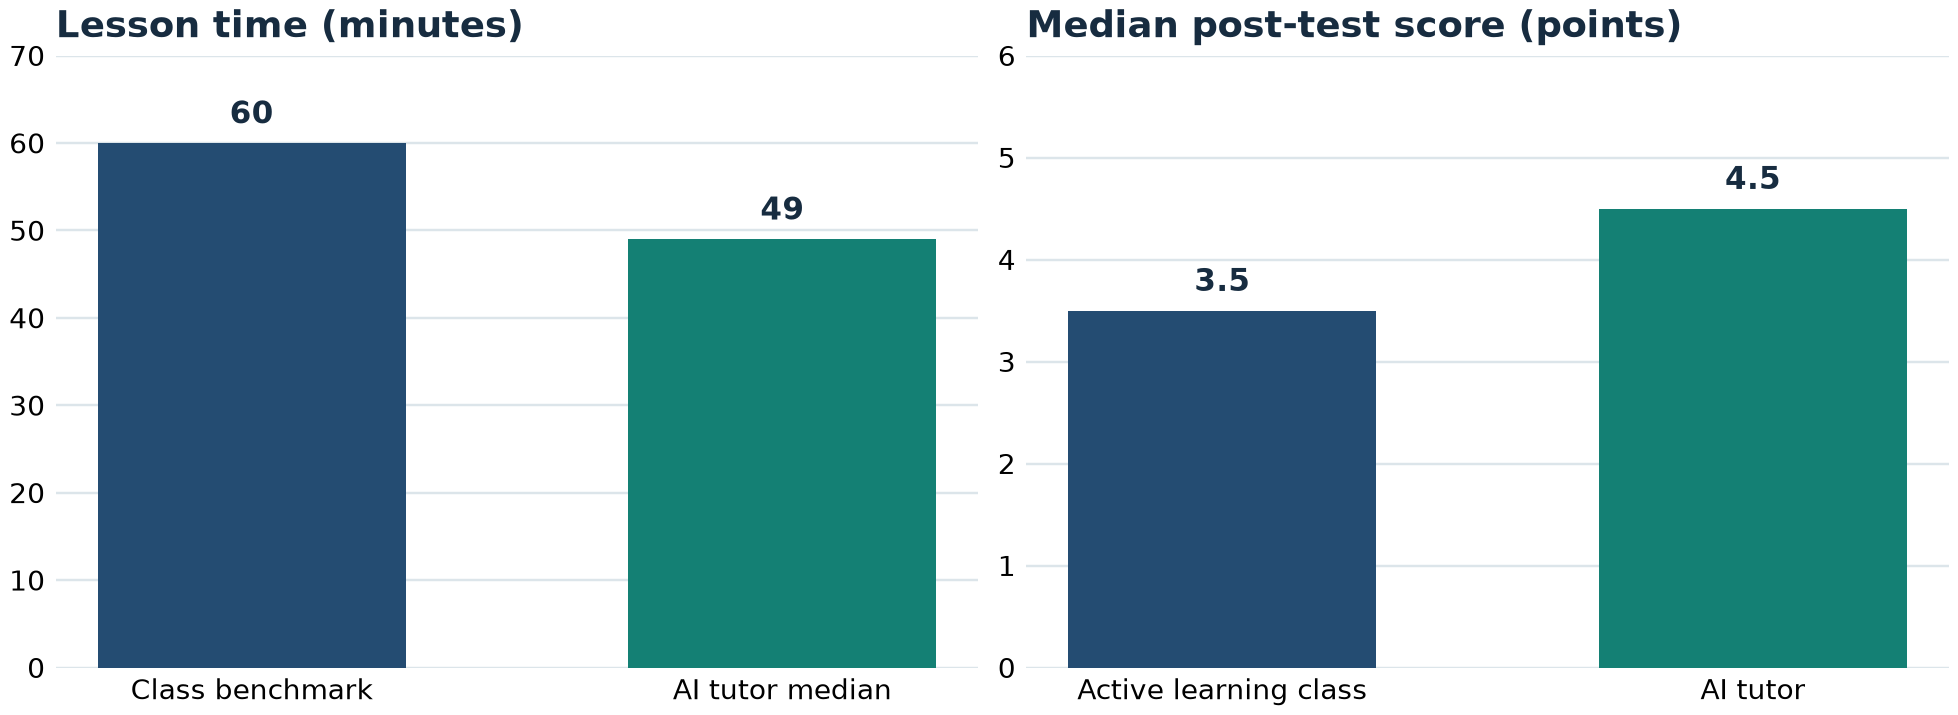

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(8.9, 3.25), layout="constrained")
university_results = {row[0]: row for row in q6}

for ax, key, title, limit, labels in [
    (axes[0], "duration", "Lesson time (minutes)", 70, ("Class benchmark", "AI tutor median")),
    (axes[1], "quiz", "Median post-test score (points)", 6, ("Active learning class", "AI tutor")),
]:
    row = university_results[key]
    values = [row[4], row[6]]
    bars = ax.bar(labels, values, color=[blue, teal], width=0.58)
    ax.bar_label(bars, labels=[f"{value:g}" for value in values], padding=4, color=ink, fontweight="bold")
    ax.set_title(title, loc="left", color=ink, fontweight="bold")
    ax.set_ylim(0, limit)
    ax.grid(axis="y", color="#dce5ea")
    ax.set_axisbelow(True)
    ax.spines[:].set_visible(False)
    ax.tick_params(length=0, labelsize=9)
plt.show()


### Interpretation and limits

The school trial measures practice with resources and then an exam without them. The university trial measures two lessons and an immediate post-test. The two studies use different populations, settings and outcome definitions. The notebook presents comparisons within each trial. It contains no individual records, common long-term measure or comparable high school time logs.

OpenAI Codex assisted with research, database design, SQL, figures and drafting. The source values and query outputs were verified during preparation.